# D1 · Purchasing patterns at the training cutoff

How large is a typical basket and how often do customers buy the same product again? Run the notebook in order on CPU. It describes eligible baskets completed from **1 December 2010 through 30 September 2011** using every merchandise credit matched before 1 October. The four models share this accounting-based target for net retained purchases. It writes four CSV tables, a JSON summary and three figures to `results/training_eda/`. [D1 cleaning](project2_colab.ipynb) · [Research plan, §2](../docs/CS5481_Project2_Research_Development_Plan_3.4.en.md) · [UCI Online Retail, Chen (2015), CC BY 4.0](https://doi.org/10.24432/C5BW33)

# D1 · 训练截止时点的购买模式

一张购物篮通常包含几种商品？客户多常再次购买同一种商品？选择 CPU，按顺序运行本 notebook。样本是 **2010 年 12 月 1 日至 2011 年 9 月 30 日**完成的有效购物篮，扣减 10 月 1 日前已匹配的全部商品贷项。四个模型共用这一定义，它根据账面的净保留件数衡量有效购买。四份 CSV 统计表、一份 JSON 摘要和三张图保存到 `results/training_eda/`。[D1 清洗](project2_colab.ipynb) · [研究计划第 2 节](../docs/CS5481_Project2_Research_Development_Plan_3.4.md) · [UCI Online Retail，Chen（2015），CC BY 4.0](https://doi.org/10.24432/C5BW33)

## Open the training snapshot

In Colab, authorize Drive access. The default project folder is `My Drive/CS5481_Project2_OnlineRetail`. The notebook reads `training_purchase_lines.csv.gz` and `training_basket_events.csv.gz` in `data/processed/` and checks both SHA-256 digests against `results/data_manifest.json`. If the files are missing or belong to the earlier cancellation-only policy, Colab downloads the three files from D1 revision `f94db090` into the temporary runtime. The EDA results go to your Drive project. Locally, use a checkout containing the outputs of the D1 cleaning step.

## 读取训练截止时点的快照

在 Colab 授权挂载 Drive。默认项目文件夹为 `我的云端硬盘/CS5481_Project2_OnlineRetail`。从 `data/processed/` 读取 `training_purchase_lines.csv.gz` 和 `training_basket_events.csv.gz`，分别按 `results/data_manifest.json` 核对 SHA-256。若三份输入不齐或仍采用旧的仅扣减取消单口径，Colab 会将 D1 版本 `f94db090` 的文件下载到临时运行环境，分析结果仍写入 Drive 项目文件夹。本地运行时，使用已生成 D1 清洗产物的仓库。

In [1]:
from pathlib import Path
import hashlib
import json
from tempfile import TemporaryDirectory
from urllib.error import URLError
from urllib.request import urlretrieve
import pandas as pd
from IPython.display import Image, display

TRAIN_START = pd.Timestamp("2010-12-01")
TRAIN_END = pd.Timestamp("2011-10-01")


EVENT_PATH = "data/processed/training_basket_events.csv.gz"
LINE_PATH = "data/processed/training_purchase_lines.csv.gz"
MANIFEST_PATH = "results/data_manifest.json"
QUANTITY_POLICY = "net_retained_all_matched_credits_v1"


def load_training_inputs(project):
    """Load the D1 snapshot that uses only credits observed before the training cutoff."""
    manifest = json.loads((project / MANIFEST_PATH).read_text(encoding="utf-8"))
    if manifest.get("recommendation_quantity_policy") != QUANTITY_POLICY:
        raise ValueError("Run D1 cleaning to build a net retained purchase snapshot for this EDA.")
    input_hashes = {}
    if not {EVENT_PATH, LINE_PATH}.issubset(manifest["outputs"]):
        raise ValueError("Regenerate the D1 cutoff-specific training snapshot and its manifest.")
    snapshot = manifest["training_snapshot"]
    if (pd.Timestamp(snapshot["start_inclusive"]) != TRAIN_START
            or pd.Timestamp(snapshot["end_exclusive"]) != TRAIN_END
            or pd.Timestamp(snapshot["credit_time_end_exclusive"]) != TRAIN_END):
        raise ValueError("The D1 snapshot uses a different basket or credit time window.")
    for relative in (EVENT_PATH, LINE_PATH):
        with (project / relative).open("rb") as stream:
            digest = hashlib.file_digest(stream, "sha256").hexdigest()
        if digest != manifest["outputs"][relative]["sha256"]:
            raise ValueError(f"File differs from its D1 cleaning manifest: {relative}")
        input_hashes[relative] = digest
    identifiers = {"CustomerID": "string", "InvoiceNo": "string", "StockCode": "string"}
    events = pd.read_csv(project / EVENT_PATH, dtype=identifiers, keep_default_na=False,
                         parse_dates=["basket_time"])
    lines = pd.read_csv(project / LINE_PATH, dtype=identifiers, keep_default_na=False,
                        usecols=["ExcelRow", *identifiers, "InvoiceDate", "Quantity", "UnitPrice",
                                 "original_quantity", "matched_credit_units", "cancelled_units",
                                 "returned_units", "other_matched_units"],
                        parse_dates=["InvoiceDate"])
    if not lines["Quantity"].eq(lines["original_quantity"] - lines["matched_credit_units"]).all():
        raise ValueError("The surviving quantity must subtract all matched credits at the training cutoff.")
    return events, lines, input_hashes

In [2]:
try:
    from google.colab import drive
except ImportError:
    drive = None

if drive is None:
    project = Path("..") if Path.cwd().name == "notebooks" else Path(".")
else:
    drive.mount("/content/drive")
    project = Path("/content/drive/MyDrive/CS5481_Project2_OnlineRetail")
    if not project.is_dir():
        selected = input(f"Drive project folder / Drive 项目文件夹 [Enter = {project}]：").strip()
        if selected:
            project = Path(selected)
            if not project.is_absolute() or not project.is_dir():
                raise ValueError("Choose an existing Drive project folder / 请选择已有项目文件夹")

def notebook_inputs(project, allow_download):
    paths = (MANIFEST_PATH, EVENT_PATH, LINE_PATH)
    if all((project / path).is_file() for path in paths):
        manifest = json.loads((project / MANIFEST_PATH).read_text(encoding="utf-8"))
        if not allow_download or manifest.get("recommendation_quantity_policy") == QUANTITY_POLICY:
            print("D1 data / D1 数据源：", project)
            return load_training_inputs(project)
        print("Using the published net retained snapshot / 改用已发布的净保留购买快照")
    if not allow_download:
        raise FileNotFoundError("Run the D1 cleaning notebook or python -m scripts.prepare_data first. / 请先完成 D1 清洗。")
    revision = "f94db0900546a02b130241434fab6ae3b2e3686e"
    base = f"https://raw.githubusercontent.com/NobunagaK/online-retail-top10-recommendation/{revision}"
    print("D1 data from GitHub / 从 GitHub 读取固定版本：", revision)
    with TemporaryDirectory() as work:
        cached = Path(work)
        for relative in paths:
            dest = cached / relative
            dest.parent.mkdir(parents=True, exist_ok=True)
            try:
                urlretrieve(f"{base}/{relative}", dest)
            except URLError as exc:
                raise RuntimeError("Download failed. Run D1 cleaning in this Drive folder and retry. / 下载失败，请在此 Drive 文件夹运行 D1 清洗后重试。") from exc
        return load_training_inputs(cached)

all_events, all_lines, input_hashes = notebook_inputs(project, allow_download=drive is not None)
output_dir = project / "results/training_eda"
print("Results / 结果目录：", output_dir)

D1 data / D1 数据源： .


Results / 结果目录： results/training_eda


## What was still in a basket at the cutoff?

Start with the original identified sale line. Subtract all units on supported merchandise credits matched to that line and issued before **1 October 2011**. For example, a 10-unit sale and a matched 3-unit credit leave 7 units; a full offset removes that line. Other purchases can still supply the same SKU to a basket or another basket. Multiply the remaining quantity by the original unit price to calculate value in GBP. The worksheet has no independent confirmation that the customer physically kept an item.

The regional time thresholds label a matched credit as an operational cancellation or return for the business audit. Reassigning that label alone leaves the allocated units, training events and measures below unchanged. The four primary models share this target and exclude those proxy labels and counts from their inputs. Each earlier D2 monthly query must reconstruct the history known at its own cutoff. A UK threshold check (72 versus 120 hours) verifies the same allocations, histories and pre-catalog labels for February–October. [Threshold check](../results/net_retention_threshold_check.csv)

The basket retains its original completion time. The first check demonstrates that the 74,215 units on invoice 541431 no longer contribute an event after C541433. The following tables show the largest remaining lines and partial credits that include operational returns. The final columns show the total matched units and their audit categories, including linked credits with an unknown region.

## 截至训练截止时，购物篮还保留哪些商品？

从有客户编号的原正单明细出发，扣减 **2011 年 10 月 1 日前**已经发生、并匹配到该行的全部商品贷项件数。例如买入 10 件后匹配到 3 件贷项，还剩 7 件；全额冲减则这一行不再产生事件。同一篮的其他购买明细，或其他购物篮，仍可能保留该商品。金额按净剩余件数乘原销售单价计算。工作簿没有独立的实物签收或留存确认。

地区时间门槛用于解释已匹配贷项，将其标为业务代理意义上的取消或退货。只改变类别名称，不改变已匹配件数、训练事件和下列统计。四个主模型共用该购买目标，均不将代理类别及其计数作为输入特征。D2 构建更早的月度查询时，需要按各自截止时间重建当时可见的购买历史。英国门槛按 72 小时和 120 小时作对照，已核对 2 月至 10 月的分配、历史以及目录筛选前的月末标签均一致。[门槛对照表](../results/net_retention_threshold_check.csv)

整篮保留原完成时间。先核验发票 541431 的 74,215 件在 C541433 生效后不再产生事件。随后查看净件数最大的保留明细，以及发生部分冲减且含业务退货的例子。最后几列给出已匹配总件数及其审计类别，包括地区不明但已匹配的贷项。

In [3]:
INVOICE_KEYS = ["CustomerID", "InvoiceNo"]
def select_training_data(
    events: pd.DataFrame, purchase_lines: pd.DataFrame, start=TRAIN_START, end=TRAIN_END,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Select whole baskets in [start, end) and their retained purchase lines.

    The event table supplies one completion time per (CustomerID, InvoiceNo).
    A basket completed at the cutoff is excluded even if some lines are earlier.
    Inputs with credit adjustments must already reflect only information available
    at the requested cutoff. Filtering dates cannot undo a later credit.
    Read CSV identifiers as strings to preserve their original spelling and zeros.
    """
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    if start >= end:
        raise ValueError("The training start must be earlier than the end.")
    times = pd.to_datetime(events["basket_time"])
    selected = times.ge(start) & times.lt(end)
    train_events = events.loc[selected].copy()
    train_events["basket_time"] = times.loc[selected]
    train_events = train_events.sort_values(
        ["basket_time", *INVOICE_KEYS, "StockCode"], ignore_index=True,
    )
    baskets = train_events[[*INVOICE_KEYS, "basket_time"]].drop_duplicates()
    train_lines = purchase_lines.merge(
        baskets, on=INVOICE_KEYS, how="inner", validate="many_to_one", suffixes=("_source", ""),
    )
    if "basket_time_source" in train_lines:
        if not pd.to_datetime(train_lines.pop("basket_time_source")).eq(train_lines["basket_time"]).all():
            raise ValueError("Purchase lines and events disagree on their original basket completion time.")
    train_lines["InvoiceDate"] = pd.to_datetime(train_lines["InvoiceDate"])
    if train_lines["InvoiceDate"].gt(train_lines["basket_time"]).any():
        raise ValueError("A retained invoice line is dated after its basket's completion.")
    if len(train_lines) != train_events["source_lines"].sum():
        raise ValueError("Training basket source-line counts differ from the matched purchase lines.")
    return train_events, train_lines.sort_values("ExcelRow", ignore_index=True)


events, lines = select_training_data(all_events, all_lines)
assert events["basket_time"].ge(TRAIN_START).all() and events["basket_time"].lt(TRAIN_END).all()
assert events["source_lines"].sum() == len(lines)
assert events["quantity"].sum() == lines["Quantity"].sum()
import math
assert math.isclose(events["amount_gbp"].sum(), (lines["Quantity"] * lines["UnitPrice"]).sum(), abs_tol=1e-6, rel_tol=0)
display(pd.Series({
    "first_completed": events["basket_time"].min(), "last_completed": events["basket_time"].max(),
    "source_lines": len(lines), "basket_item_events": len(events),
    "baskets": len(events[INVOICE_KEYS].drop_duplicates()),
    "customers": events["CustomerID"].nunique(), "items": events["StockCode"].nunique(),
}).to_frame("training_window"))
assert len(events) == len(all_events) and len(lines) == len(all_lines)
assert (lines["Quantity"] == lines["original_quantity"] - lines["matched_credit_units"]).all()
example = events["InvoiceNo"].eq("541431") & events["StockCode"].eq("23166")
assert not example.any()
print("541431 / 23166 active events at cutoff / 截止时有效事件数", int(example.sum()))
evidence_columns = ["ExcelRow", "CustomerID", "InvoiceNo", "StockCode", "InvoiceDate",
                    "original_quantity", "Quantity", "UnitPrice", "matched_credit_units", "cancelled_units", "returned_units", "other_matched_units"]
display(lines.nlargest(3, "Quantity")[evidence_columns])
display(lines.loc[lines["returned_units"].gt(0), evidence_columns].head(3))

,training_window
first_completed,2010-12-01 08:26:00
last_completed,2011-09-30 15:52:00
source_lines,260919
basket_item_events,258532
baskets,13001
customers,3608
items,3495


541431 / 23166 active events at cutoff / 截止时有效事件数 0


,ExcelRow,CustomerID,InvoiceNo,StockCode,InvoiceDate,original_quantity,Quantity,UnitPrice,matched_credit_units,cancelled_units,returned_units,other_matched_units
139917,206123,13135,554868,22197,2011-05-27 10:52:00,4300,4300,0.72,0,0,0,0
60010,97434,18087,544612,22053,2011-02-22 10:43:00,3906,3906,0.82,0,0,0,0
184465,270887,14609,560599,18007,2011-07-19 17:04:00,3186,3186,0.06,0,0,0,0


,ExcelRow,CustomerID,InvoiceNo,StockCode,InvoiceDate,original_quantity,Quantity,UnitPrice,matched_credit_units,cancelled_units,returned_units,other_matched_units
64,67,15100,536374,21258,2010-12-01 09:09:00,32,20,10.95,12,0,12,0
95,98,14688,536378,21212,2010-12-01 09:37:00,120,118,0.42,2,0,2,0
97,100,14688,536378,21977,2010-12-01 09:37:00,24,23,0.55,1,0,1,0


## How does purchasing activity change by month?

Count customers within each month of basket completion. A returning customer can appear in several months. Events, units and purchase amounts can be summed across months. The busiest month by baskets was **2011-09** (1,733); the largest event count was 39,066 in 2011-09, and the smallest was 19,309 in 2011-02.

## 每个月的交易量怎样变化？

按购物篮完成月份统计不同客户，同一位回头客可能出现在多个月份。事件、件数与购买金额可以跨月相加。**2011-09** 的购物篮最多（1,733 个）。事件最多的是 2011-09（39,066 次），最少的是 2011-02（19,309 次）。

In [4]:
def monthly_activity(train_events: pd.DataFrame, start=TRAIN_START, end=TRAIN_END) -> pd.DataFrame:
    """Summarize each calendar month, including empty months within [start, end).

    Each basket and all its item events belong to its completion month. Customer
    counts are monthly distinct customers. Amounts preserve sub-penny GBP.
    """
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    if start >= end:
        raise ValueError("The training start must be earlier than the end.")
    times = pd.to_datetime(train_events["basket_time"])
    selected = times.ge(start) & times.lt(end)
    events = train_events.loc[selected].assign(month=times.loc[selected].dt.to_period("M"))
    monthly = events.groupby("month").agg(
        active_customers=("CustomerID", "nunique"),
        basket_item_events=("StockCode", "size"),
        source_lines=("source_lines", "sum"),
        units=("quantity", "sum"),
        amount_gbp=("amount_gbp", "sum"),
    )
    baskets = events[["month", *INVOICE_KEYS]].drop_duplicates()
    monthly.insert(1, "baskets", baskets.groupby("month").size())
    months = pd.period_range(start, end - pd.Timedelta(nanoseconds=1), freq="M", name="month")
    monthly = monthly.reindex(months, fill_value=0)
    monthly.index = monthly.index.astype(str)
    return monthly.reset_index()
monthly = monthly_activity(events)
assert monthly["basket_item_events"].sum() == len(events)
assert monthly["source_lines"].sum() == len(lines)
display(monthly)

,month,active_customers,baskets,basket_item_events,source_lines,units,amount_gbp
0,2010-12,882,1386,25027,25386,305337,550695.470
1,2011-01,737,975,20510,20725,261567,453973.100
2,2011-02,756,987,19309,19516,263063,436059.850
3,2011-03,970,1303,26228,26479,342102,571770.850
4,2011-04,849,1130,22058,22212,287461,447976.671
5,2011-05,1051,1529,27572,27765,367315,646793.020
6,2011-06,987,1380,26406,26604,355216,602077.440
7,2011-07,945,1314,26038,26270,362430,581216.321
8,2011-08,933,1264,26318,26551,387716,616448.410
9,2011-09,1257,1733,39066,39411,540077,930026.601


## What does a typical purchase look like?

Every surviving source line contributes one original unit price and one net retained quantity. Every customer invoice contributes one basket size. Every customer contributes one history length, counting one event per distinct basket–SKU including later purchases of the same SKU. The median line price was £1.95 and the median net retained quantity was 6 units. The median basket contained 15 distinct products. Across customers the median history was 34 events, and the median basket count was 2. Percentiles use linear interpolation.

## 典型的一次购买是什么样？

每条保留的原始明细贡献一次原单价和一次剩余净保留件数，每张客户发票贡献一个购物篮大小，每位客户贡献一个历史长度。同一篮中的同一商品计一次事件，后来再购买该商品仍计入历史。明细单价中位数为 £1.95，净保留件数中位数为 6 件。每篮商品种数中位数为 15，每位客户的历史长度中位数为 34 次事件，购物篮数中位数为 2。分位数使用线性插值。

In [5]:
def distribution_tables(
    train_events: pd.DataFrame, train_lines: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Return exact-value frequencies and summaries of five training distributions.

    Original unit price and surviving quantity are observed once per active
    source line, with no quantity weighting. Basket size counts distinct SKUs per completed customer invoice.
    History length counts basket-item events per customer across the full training
    window, including repeat purchases on later invoices. Basket frequency counts
    distinct completed invoices per customer in that same window. Quantiles use
    linear interpolation on the individual observations.
    """
    baskets = train_events.groupby(INVOICE_KEYS)["StockCode"].nunique()
    distributions = {
        "line_unit_price_gbp": (train_lines["UnitPrice"], "source line", "GBP per unit"),
        "line_quantity": (train_lines["Quantity"], "source line", "units"),
        "basket_distinct_skus": (baskets, "basket", "distinct SKUs"),
        "customer_history_events": (
            train_events.groupby("CustomerID").size(), "customer", "basket-item events",
        ),
        "customer_baskets": (
            baskets.groupby(level="CustomerID").size(), "customer", "baskets",
        ),
    }
    frequencies, summaries = [], []
    quantiles = {"p25": .25, "median": .5, "p75": .75, "p90": .90, "p95": .95, "p99": .99}
    for measure, (observations, observation_unit, value_unit) in distributions.items():
        counts = observations.value_counts().sort_index().rename_axis("value")
        frequencies.append(counts.rename("frequency").reset_index().assign(measure=measure))
        percentiles = observations.quantile(list(quantiles.values()))
        summaries.append({
            "measure": measure,
            "observation_unit": observation_unit,
            "value_unit": value_unit,
            "count": len(observations),
            "min": observations.min(),
            **{name: percentiles.loc[q] for name, q in quantiles.items()},
            "max": observations.max(),
            "mean": observations.mean(),
        })
    frequency_table = pd.concat(frequencies, ignore_index=True)[["measure", "value", "frequency"]]
    return frequency_table, pd.DataFrame(summaries)
frequency, distributions = distribution_tables(events, lines)
assert frequency.groupby("measure")["frequency"].sum().to_dict() == distributions.set_index("measure")["count"].to_dict()
display(distributions)
display(frequency.loc[frequency["measure"].eq("line_unit_price_gbp")].head())

,measure,observation_unit,value_unit,count,min,p25,median,p75,p90,p95,p99,max,mean
0,line_unit_price_gbp,source line,GBP per unit,260919,0.001,1.25,1.95,3.75,6.75,8.5,12.75,649.5,2.919636
1,line_quantity,source line,units,260919,1.000,2.00,6.00,12.00,24.00,47.0,144.00,4300.0,13.307900
2,basket_distinct_skus,basket,distinct SKUs,13001,1.000,6.00,15.00,26.00,43.00,57.0,93.00,418.0,19.885547
3,customer_history_events,customer,basket-item events,3608,1.000,15.00,34.00,79.00,161.00,246.3,499.86,4765.0,71.655211
4,customer_baskets,customer,baskets,3608,1.000,1.00,2.00,4.00,8.00,11.0,24.00,136.0,3.603381


,measure,value,frequency
0,line_unit_price_gbp,0.001,3
1,line_unit_price_gbp,0.040,39
2,line_unit_price_gbp,0.060,58
3,line_unit_price_gbp,0.070,6
4,line_unit_price_gbp,0.080,34


## Which products reach the most customers?

Rank exact StockCodes by the number of distinct customers purchasing them, then by ascending code when counts tie. The top 10% rounded up comprises **350 of 3,495 SKUs** and accounts for 120,733 of 258,532 events (46.70%). The leading item, 22423, reached 744 distinct customers. These figures describe purchases. Measuring popularity in recommendations requires model predictions.

## 哪些商品覆盖的购买客户最多？

按购买每个原始商品码的不同客户数降序排列，同值按商品码升序排列。热门组取前 10% 并向上取整，共 **3,495 种商品中的 350 种**，占 258,532 次事件中的 120,733 次（46.70%）。排名第一的商品 22423 有 744 位购买客户。这些结果描述实际购买的集中度，衡量推荐结果的热门偏好仍需要模型预测。

In [6]:
def _share(numerator: int, denominator: int) -> float | None:
    return numerator / denominator if denominator else None

item_key = ["CustomerID", "InvoiceNo", "StockCode"]
if events[[*item_key, "basket_time"]].isna().any().any():
    raise ValueError("Each basket-item event needs a customer, invoice, SKU and completion time.")
if events.duplicated(item_key).any():
    raise ValueError("Expected one event per customer, invoice and SKU.")

customers = int(events["CustomerID"].nunique())
popularity = (
    events.groupby("StockCode", as_index=False, sort=False, observed=True)
    .agg(purchasing_customers=("CustomerID", "nunique"), basket_item_events=("InvoiceNo", "size"))
    .sort_values(["purchasing_customers", "StockCode"], ascending=[False, True], ignore_index=True)
)
items = len(popularity)
# Integer ceiling gives exactly the leading 10% (rounded up), even with ties.
head_items = (items + 9) // 10
popularity.insert(0, "rank", range(1, items + 1))
popularity.insert(3, "customer_reach_share", popularity["purchasing_customers"] / customers)
popularity["is_head"] = popularity["rank"].le(head_items)
head = popularity.loc[popularity["is_head"]]
head_events = int(head["basket_item_events"].sum())
head_customers = int(events.loc[events["StockCode"].isin(head["StockCode"]), "CustomerID"].nunique())
display(popularity.head(10))
print("Top items / 热门商品数：", head_items)

,rank,StockCode,purchasing_customers,customer_reach_share,basket_item_events,is_head
0,1,22423,744,0.206208,1311,True
1,2,85123A,726,0.201220,1539,True
2,3,47566,645,0.178769,1192,True
3,4,21212,542,0.150222,803,True
4,5,22720,530,0.146896,866,True
5,6,84879,527,0.146064,990,True
6,7,85099B,517,0.143293,1182,True
7,8,22960,489,0.135532,695,True
8,9,22457,483,0.133869,731,True
9,10,23298,482,0.133592,789,True


Top items / 热门商品数： 350


## When does an event count as a repeat purchase?

For a customer and SKU, compare each surviving event with the earliest surviving basket completion time in the same training snapshot. An event counts as a repeat only if there was a strictly earlier retained purchase. Tied first timestamps do not establish order. The examples below show the same customer–SKU on different dates or at a tied first timestamp. The statistic describes repetition among retained events. The separate post-return audit starts its clock at a credit. The `return_repurchase` worksheet reports a strictly later sale of the same SKU to the same customer on another invoice after 1,579 of 4,220 operational return credits for fewer units than the original sale line (37.42%). That percentage counts credit rows, with follow-up starting at each credit. [Post-return audit](../results/transaction_exceptions.xlsx)

## 什么时候算作一次复购？

对同一客户和商品，将每个净保留事件与本次快照中其最早的净保留购物篮完成时间比较。有严格更早的保留购买，该事件才计作复购。首次时间相同无法确定先后顺序。下方示例展示同一客户、同一商品在不同日期出现，以及首次时间并列。此处衡量净保留购买事件中的复购；另行分析退货后是否再次购买时，从贷项发生时计算。`return_repurchase` 工作表以每条贷项为起点。在 4,220 条分类为退货且冲减件数少于原销售明细件数的贷项中，有 1,579 条之后出现时间严格更晚、发票不同的同客同品销售，占 37.42%。这里的分母是贷项行数。[退货后再购审计](../results/transaction_exceptions.xlsx)

In [7]:
pair_key = ["CustomerID", "StockCode"]
pairs = events.groupby(pair_key, sort=False, observed=True)
observed_pairs = pairs.ngroups
possible_pairs = customers * items
# Two invoices at the same first completion time do not provide earlier
# history for one another. The unique event key makes any later match a
# different invoice for this customer and SKU.
repeat = events["basket_time"].gt(pairs["basket_time"].transform("min"))
repeat_events = int(repeat.sum())
repeat_pairs = len(events.loc[repeat, pair_key].drop_duplicates())
event_count = len(events)

summary = {
    "customers": customers,
    "items": items,
    "basket_item_events": event_count,
    "observed_customer_item_pairs": observed_pairs,
    "possible_customer_item_pairs": possible_pairs,
    "interaction_sparsity": 1 - observed_pairs / possible_pairs if possible_pairs else None,
    "repeat_purchase_events": repeat_events,
    "repeat_event_share": _share(repeat_events, event_count),
    "repeated_customer_item_pairs": repeat_pairs,
    "repeated_pair_share": _share(repeat_pairs, observed_pairs),
    "head_items": head_items,
    "head_purchase_events": head_events,
    "head_event_share": _share(head_events, event_count),
    "head_purchasing_customers": head_customers,
    "head_customer_reach_share": _share(head_customers, customers),
}
preferences = summary
display(pd.Series({
    "Repeat events / 复购事件": f"{repeat_events:,}",
    "All purchase events / 全部购买事件": f"{event_count:,}",
    "Repeat event share / 事件复购率": f"{preferences['repeat_event_share']:.2%}",
    "Repeated pairs / 发生复购的客户商品组合": f"{repeat_pairs:,}",
    "Observed pairs / 有购买记录的组合": f"{observed_pairs:,}",
    "Repeated pair share / 已购组合中发生复购的比例": f"{preferences['repeated_pair_share']:.2%}",
    "Possible pairs / 可能组合": f"{possible_pairs:,}",
    "Interaction sparsity / 稀疏度": f"{preferences['interaction_sparsity']:.2%}",
}).to_frame("training_value"))
trace = events.loc[
    (events["CustomerID"].eq("12540") & events["StockCode"].eq("85123A")) |
    (events["CustomerID"].eq("12971") & events["StockCode"].eq("21448")),
    ["CustomerID", "StockCode", "InvoiceNo", "basket_time", "quantity"],
].copy()
trace["strictly_later_repeat"] = repeat.loc[trace.index]
display(trace)

,training_value
Repeat events / 复购事件,"71,073"
All purchase events / 全部购买事件,"258,532"
Repeat event share / 事件复购率,27.49%
Repeated pairs / 发生复购的客户商品组合,"38,280"
Observed pairs / 有购买记录的组合,"187,452"
Repeated pair share / 已购组合中发生复购的比例,20.42%
Possible pairs / 可能组合,"12,609,960"
Interaction sparsity / 稀疏度,98.51%


,CustomerID,StockCode,InvoiceNo,basket_time,quantity,strictly_later_repeat
87628,12971,21448,547944,2011-03-28 14:59:00,12,False
87631,12971,21448,547946,2011-03-28 14:59:00,12,False
109691,12971,21448,550967,2011-04-21 16:58:00,12,True
187167,12540,85123A,561093,2011-07-25 10:01:00,12,False
246601,12540,85123A,568001,2011-09-23 11:35:00,12,True


## How frequent are repeats, and how sparse are the observations?

71,073 of 258,532 net retained basket-item events (27.49%) follow an earlier purchase of the same SKU by the same customer. At the customer–SKU level, 38,280 of 187,452 observed pairs (20.42%) have a repeat. Subtracting distinct pairs from all events would add 7 events tied at the first timestamp. The 3,608 active customers and 3,495 observed SKUs give 12,609,960 possible pairs and **98.51% sparsity**. An unobserved pair means no qualifying purchase appears in this window.

## 复购有多常见？购买记录有多稀疏？

258,532 次净保留篮内商品事件中，71,073 次能找到同一客户在严格更早时购买同一商品的记录（27.49%）。以客户–商品组合计算，在 187,452 个已购组合中，38,280 个出现复购（20.42%）。直接用总事件数减去不同组合数，会多算 7 个在首次购买时并列的事件。3,608 位活跃客户与 3,495 种已购商品构成 12,609,960 个可能组合，**稀疏度为 98.51%**。未观察到的组合表示该窗口中没有符合口径的购买记录。

## Draw the distributions from the exported counts

The monthly figure uses the monthly table. The distribution curves use the exact-value frequency table, including the extremes. The popularity figure uses the same sorted SKU list as the reported head count. Axis labels identify what is counted and in which units.

## 从统计表绘制结果图

月度图使用月度统计表；分布图使用各个取值的精确频数，包括极端值；商品热度图沿用热门组统计时的排序结果。每个坐标轴均注明所统计的对象或单位。

In [8]:
from matplotlib.figure import Figure
from matplotlib.ticker import FuncFormatter, MaxNLocator
import pandas as pd


BLUE = "#245e85"
TEAL = "#137563"
INK = "#1f3544"


def _number(value, position=None):
    if abs(value) >= 1_000_000:
        return f"{value / 1_000_000:g}M"
    if abs(value) >= 1_000:
        return f"{value / 1_000:g}k"
    return f"{value:,.6f}".rstrip("0").rstrip(".")


def _heading(figure, title, subtitle):
    figure.text(0.075, 0.97, title, va="top", fontsize=17, fontweight="bold", color=INK)
    figure.text(0.075, 0.915, subtitle, va="top", fontsize=10, color=INK)


def _style(axis):
    axis.spines[["top", "right"]].set_visible(False)
    axis.spines[["bottom", "left"]].set_color("#899aa3")
    axis.tick_params(labelsize=9, labelcolor=INK, color="#899aa3")
    axis.grid(axis="y", which="major", color="#dbe1e4", linewidth=0.7)
    axis.set_axisbelow(True)


def _monthly(monthly, window):
    figure = Figure(figsize=(11, 7))
    axes = figure.subplots(2, 2, sharex=True).flat
    figure.subplots_adjust(left=0.08, right=0.985, top=0.80, bottom=0.13, hspace=0.35, wspace=0.21)
    _heading(figure, "Monthly net retained purchases", f"{window}  ·  Month of basket completion")
    panels = [
        ("baskets", "Customer invoices (baskets)"),
        ("basket_item_events", "Distinct items summed across baskets (events)"),
        ("units", "Net retained units"),
        ("amount_gbp", "Net retained amount at sale prices (GBP)"),
    ]
    month_labels = pd.PeriodIndex(monthly["month"], freq="M").strftime("%b\n%Y")
    for axis, (column, title) in zip(axes, panels):
        _style(axis)
        axis.bar(range(len(monthly)), monthly[column], color=BLUE, width=0.70)
        axis.set_title(title, fontsize=11, loc="left", color=INK)
        axis.set_ylim(bottom=0)
        axis.yaxis.set_major_locator(MaxNLocator(nbins=5, integer=column != "amount_gbp"))
        axis.yaxis.set_major_formatter(FuncFormatter(_number))
        axis.set_xticks(range(len(monthly)), month_labels)
    return figure

In [9]:
def _distributions(distributions, window):
    figure = Figure(figsize=(12, 7.4))
    grid = figure.add_gridspec(2, 6, left=0.075, right=0.975, top=0.785,
                               bottom=0.09, wspace=0.78, hspace=0.52)
    _heading(figure, "Distribution of net retained purchase lines, baskets and customer histories",
             f"{window}  ·  Share at or above each observed value  ·  Both axes logarithmic  ·  Full range")
    panels = [
        ("line_unit_price_gbp", "Unit price per purchase line", "GBP per unit", "Purchase lines (%)", grid[0, :3]),
        ("line_quantity", "Net retained units per line", "Units", "Purchase lines (%)", grid[0, 3:]),
        ("basket_distinct_skus", "Size of a basket", "Distinct SKUs", "Baskets (%)", grid[1, :2]),
        ("customer_history_events", "Events per customer", "Basket-item events", "Customers (%)", grid[1, 2:4]),
        ("customer_baskets", "Baskets per customer", "Completed baskets", "Customers (%)", grid[1, 4:]),
    ]
    for measure, title, unit, population, slot in panels:
        axis = figure.add_subplot(slot)
        _style(axis)
        axis.set_title(title, fontsize=11, loc="left", color=INK)
        axis.set_xlabel(unit, fontsize=10)
        axis.set_ylabel(population, fontsize=10)
        rows = distributions.loc[distributions["measure"] == measure].sort_values("value")
        if rows.empty:
            axis.text(0.5, 0.5, "No observations", transform=axis.transAxes, ha="center")
            continue
        # For an observed x, sum exact frequencies from x through the maximum.
        share = rows["frequency"].iloc[::-1].cumsum().iloc[::-1] * 100 / rows["frequency"].sum()
        axis.step(rows["value"], share, where="pre", color=TEAL, linewidth=1.8)
        axis.scatter(rows["value"].iloc[[0, -1]], share.iloc[[0, -1]], s=16, color=TEAL, zorder=3)
        axis.set_xscale("log")
        axis.set_yscale("log")
        axis.minorticks_off()
        axis.yaxis.set_major_formatter(FuncFormatter(_number))
        axis.xaxis.set_major_formatter(FuncFormatter(_number))
    return figure

In [10]:
def _popularity(popularity, window):
    figure = Figure(figsize=(10.5, 6))
    axis = figure.subplots()
    figure.subplots_adjust(left=0.10, right=0.975, top=0.80, bottom=0.14)
    _heading(figure, "Customer reach of net retained products",
             f"{window}  ·  All {len(popularity):,} training SKUs  ·  Logarithmic customer count")
    _style(axis)
    axis.set_xlabel("Item rank by number of distinct purchasing customers")
    axis.set_ylabel("Distinct customers purchasing the item")
    if not popularity.empty:
        ordered = popularity.sort_values("rank")
        head = ordered.loc[ordered["is_head"], "rank"]
        if not head.empty:
            axis.axvspan(0.5, head.max() + 0.5, color=TEAL, alpha=0.13,
                         label=f"Top 10% of items (ranks 1–{head.max():,})")
            axis.legend(loc="upper right", frameon=False, fontsize=10)
        axis.plot(ordered["rank"], ordered["purchasing_customers"], color=BLUE, linewidth=2)
        axis.set_yscale("log")
        axis.set_xlim(0.5, ordered["rank"].max() + 0.5)
        axis.minorticks_off()
    axis.yaxis.set_major_formatter(FuncFormatter(_number))
    axis.xaxis.set_major_locator(MaxNLocator(nbins=8, integer=True))
    return figure


def build_training_figures(tables: dict[str, pd.DataFrame]) -> dict[str, Figure]:
    """Build displayable, unsaved figures. The caller chooses file format and DPI."""
    monthly = tables["monthly_activity"].sort_values("month")
    periods = pd.PeriodIndex(monthly["month"], freq="M")
    window = "Training window"
    if len(periods):
        window += f" · {periods.min().strftime('%b %Y')}–{periods.max().strftime('%b %Y')}"
    return {
        "monthly_volume": _monthly(monthly, window),
        "size_distributions": _distributions(tables["distributions"], window),
        "item_popularity": _popularity(tables["item_popularity"], window),
    }

## Export the tables, figures and summary

The JSON summary records the interval, input file hashes, numerators, denominators and metric definitions. CSVs contain the ten monthly rows, exact frequencies, distribution summary and ranked SKU table. Each PNG can be used in the report. The CLI reproduces these same outputs with `python -m scripts.analyze_training`.

## 保存表格、图片与统计摘要

JSON 摘要记录日期边界、输入文件校验值、各指标的分子分母和定义。四份 CSV 依次保存月度活动、精确取值频数、分布分位数和商品热度排名。三张 PNG 图可直接用于报告。本地命令 `python -m scripts.analyze_training` 可复现相同的结果。

In [11]:
def summarize_window(train_events, train_lines, preferences, input_hashes):
    return {
        "window": {"field": "basket_time", "start_inclusive": TRAIN_START.isoformat(),
                   "end_exclusive": TRAIN_END.isoformat()},
        "recommendation_quantity_policy": QUANTITY_POLICY,
        "input_sha256": input_hashes,
        "source_lines": len(train_lines),
        "baskets": len(train_events[["CustomerID", "InvoiceNo"]].drop_duplicates()),
        "units": int(train_events["quantity"].sum()),
        "recorded_amount_gbp": float(format(train_events["amount_gbp"].sum(), ".15g")),
        **preferences,
        "definitions": {
            "source_lines": "Original positive sale lines with a positive remaining quantity at the exclusive training cutoff.",
            "units": "Original sale units less all matched credit units issued strictly before the cutoff, including operational cancellation and return proxies.",
            "recorded_amount_gbp": "Net retained units multiplied by the original sale line price, summed over surviving training purchases.",
            "repeat_event_share": "Net retained basket-item events with an earlier net retained basket for the same customer and SKU / all net retained training basket-item events. Equal timestamps provide no earlier history.",
            "repeated_pair_share": "Observed customer-SKU pairs with a strictly later purchase / all observed training customer-SKU pairs.",
            "interaction_sparsity": "1 - observed distinct customer-SKU pairs / (active customers x observed SKUs).",
            "head_items": "Ceiling of 10% of observed SKUs, ranked by distinct customers descending, then exact StockCode ascending.",
            "head_event_share": "Events for head SKUs / all training events.",
            "head_customer_reach_share": "Distinct customers with any head SKU / distinct active training customers.",
        },
    }


def save_training_eda(output_dir, tables, summary, figures):
    """Stage the tables and figures together and replace the summary last."""
    output_dir.mkdir(parents=True, exist_ok=True)
    with TemporaryDirectory(dir=output_dir) as dirname:
        staged = Path(dirname)
        paths = []
        for name, table in tables.items():
            path = staged / f"{name}.csv"
            table.to_csv(path, index=False, float_format="%.15g")
            paths.append(path)
        for name, figure in figures.items():
            path = staged / f"{name}.png"
            figure.savefig(path, format="png", dpi=170, bbox_inches="tight", facecolor="white")
            paths.append(path)
        summary_path = staged / "summary.json"
        summary_path.write_text(json.dumps(summary, indent=2, ensure_ascii=False, allow_nan=False) + "\n",
                                encoding="utf-8")
        for path in [*paths, summary_path]:
            path.replace(output_dir / path.name)


tables = {"monthly_activity": monthly, "distributions": frequency, "distribution_summary": distributions,
          "item_popularity": popularity}
summary = summarize_window(events, lines, preferences, input_hashes)
figures = build_training_figures(tables)
save_training_eda(output_dir, tables, summary, figures)
print("Saved under / 保存目录：", output_dir)

Saved under / 保存目录： results/training_eda


### Monthly activity

Read each panel on its own vertical scale. Distinct customer counts by month are included in the CSV.

### 月度活动

各面板的纵轴单位不同。逐月活跃客户数可在月度 CSV 中查看。

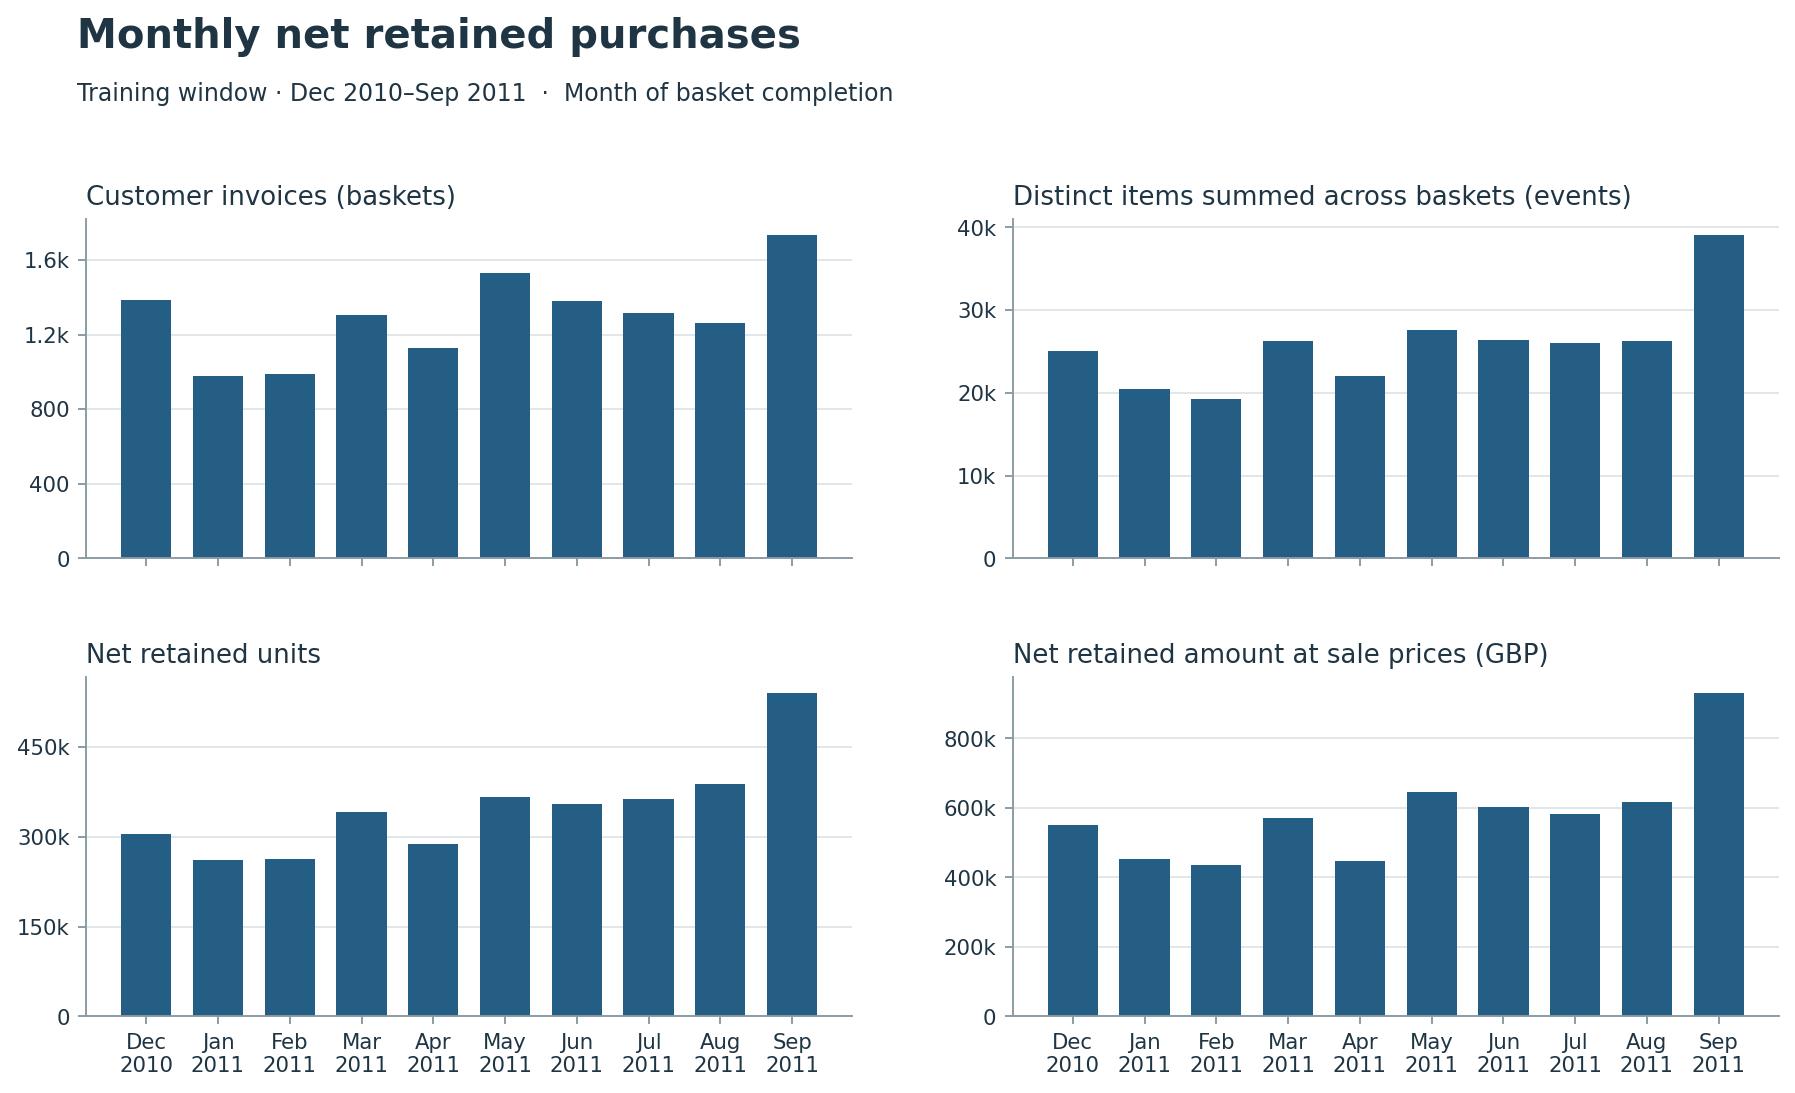

In [12]:
display(Image(filename=str(output_dir / "monthly_volume.png"), width=920))

### Size and price distributions

At each value x, the vertical axis shows the percentage of observations at or above x. Both axes are logarithmic. After subtracting all matched credits, the largest surviving purchase line contains **4,300 units**, while the lowest surviving line price is £0.001.

### 规模与价格分布

横轴的每个 x 对应观测值大于等于 x 的百分比，两轴均为对数刻度。扣减截止前全部已匹配贷项后，剩余明细的最大净保留件数为 **4,300 件**，保留明细中的最低单价为 £0.001。

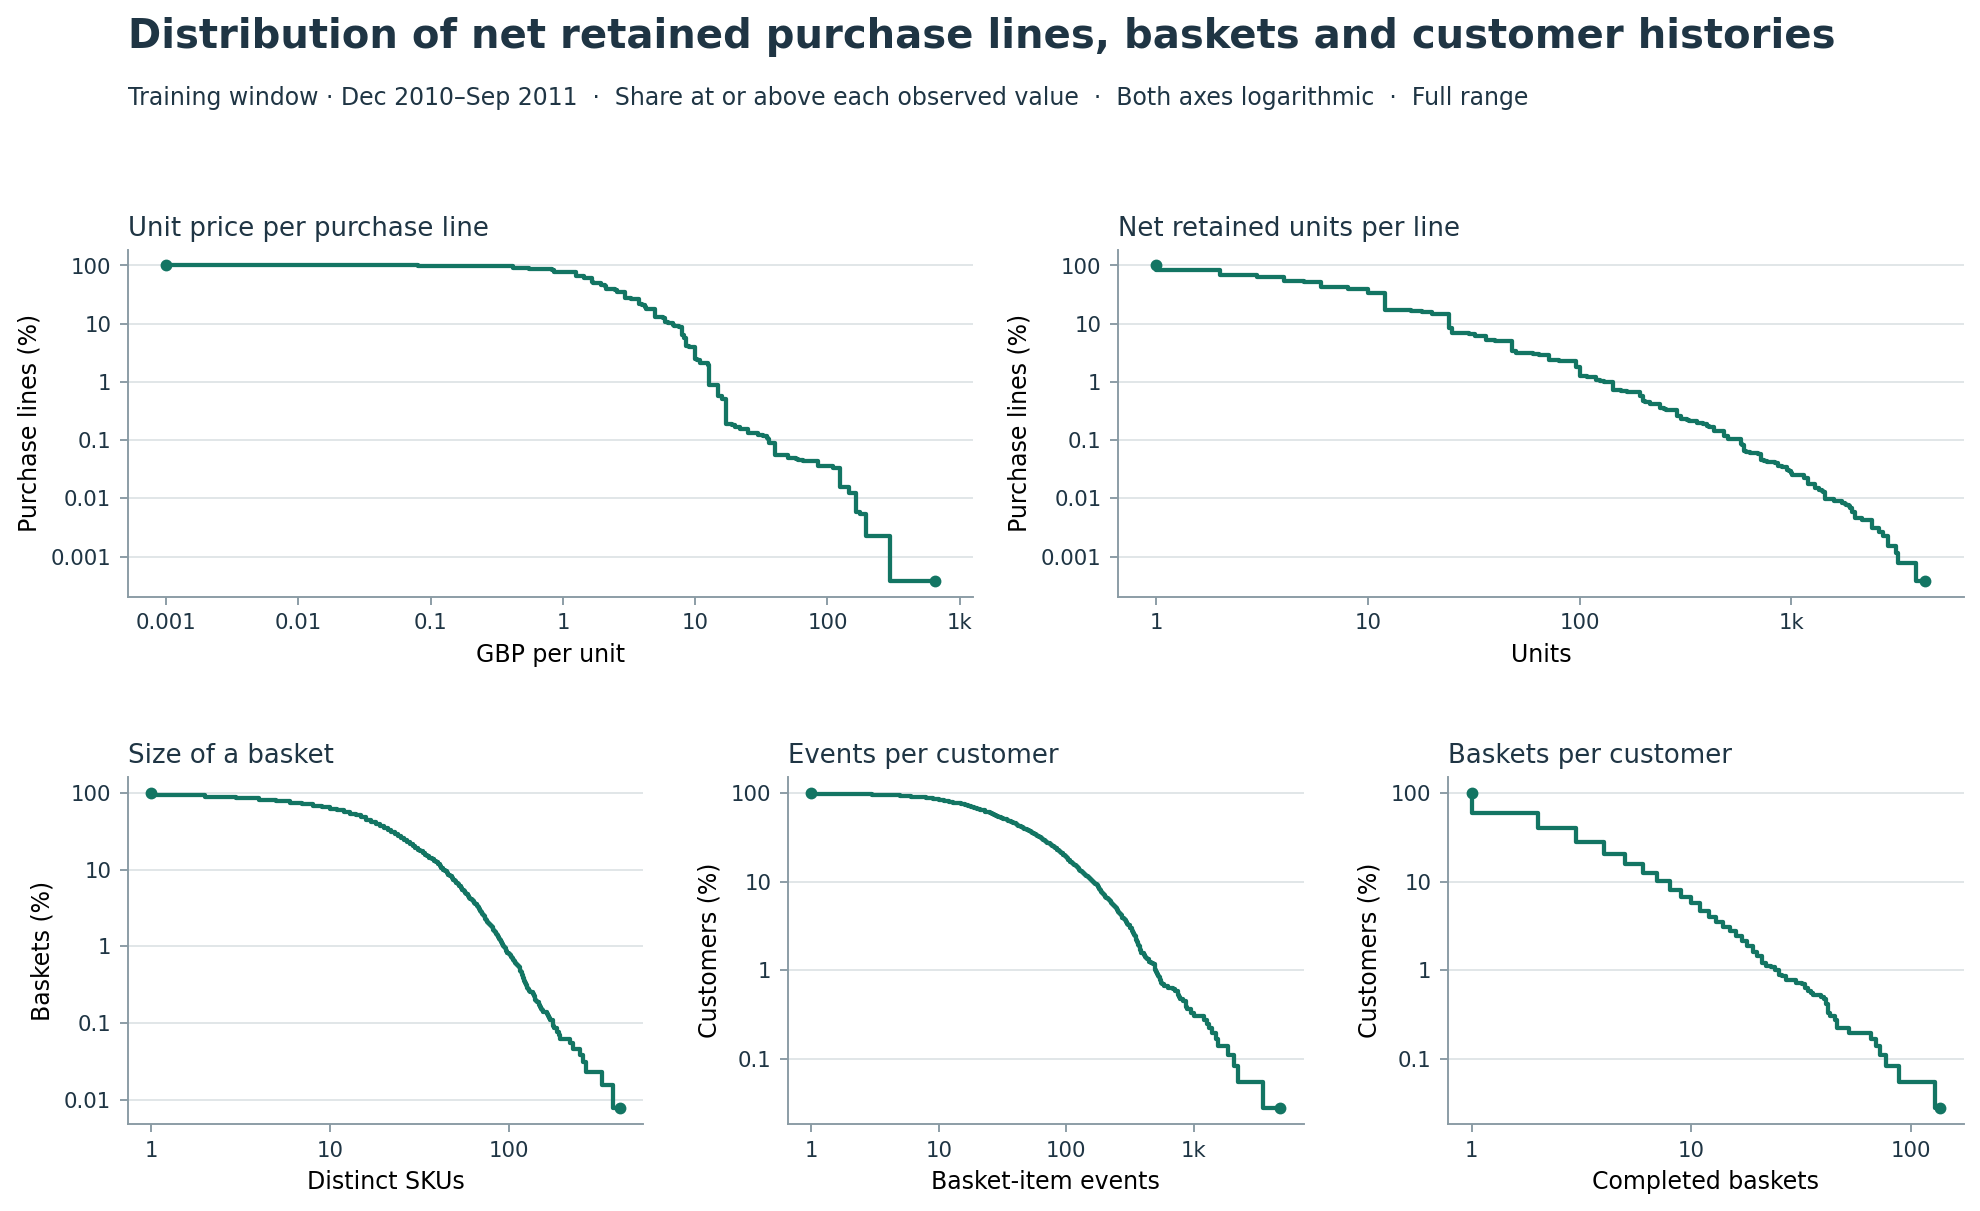

In [13]:
display(Image(filename=str(output_dir / "size_distributions.png"), width=920))

### Item popularity across the catalog

Each point represents one ranked SKU. The vertical axis is the number of distinct buyers on a log scale. Shading identifies ranks 1–350.

### 目录内商品的热度

每个排名位置对应一种商品，纵轴是对数刻度的不同购买客户数。阴影覆盖第 1 至 350 名。

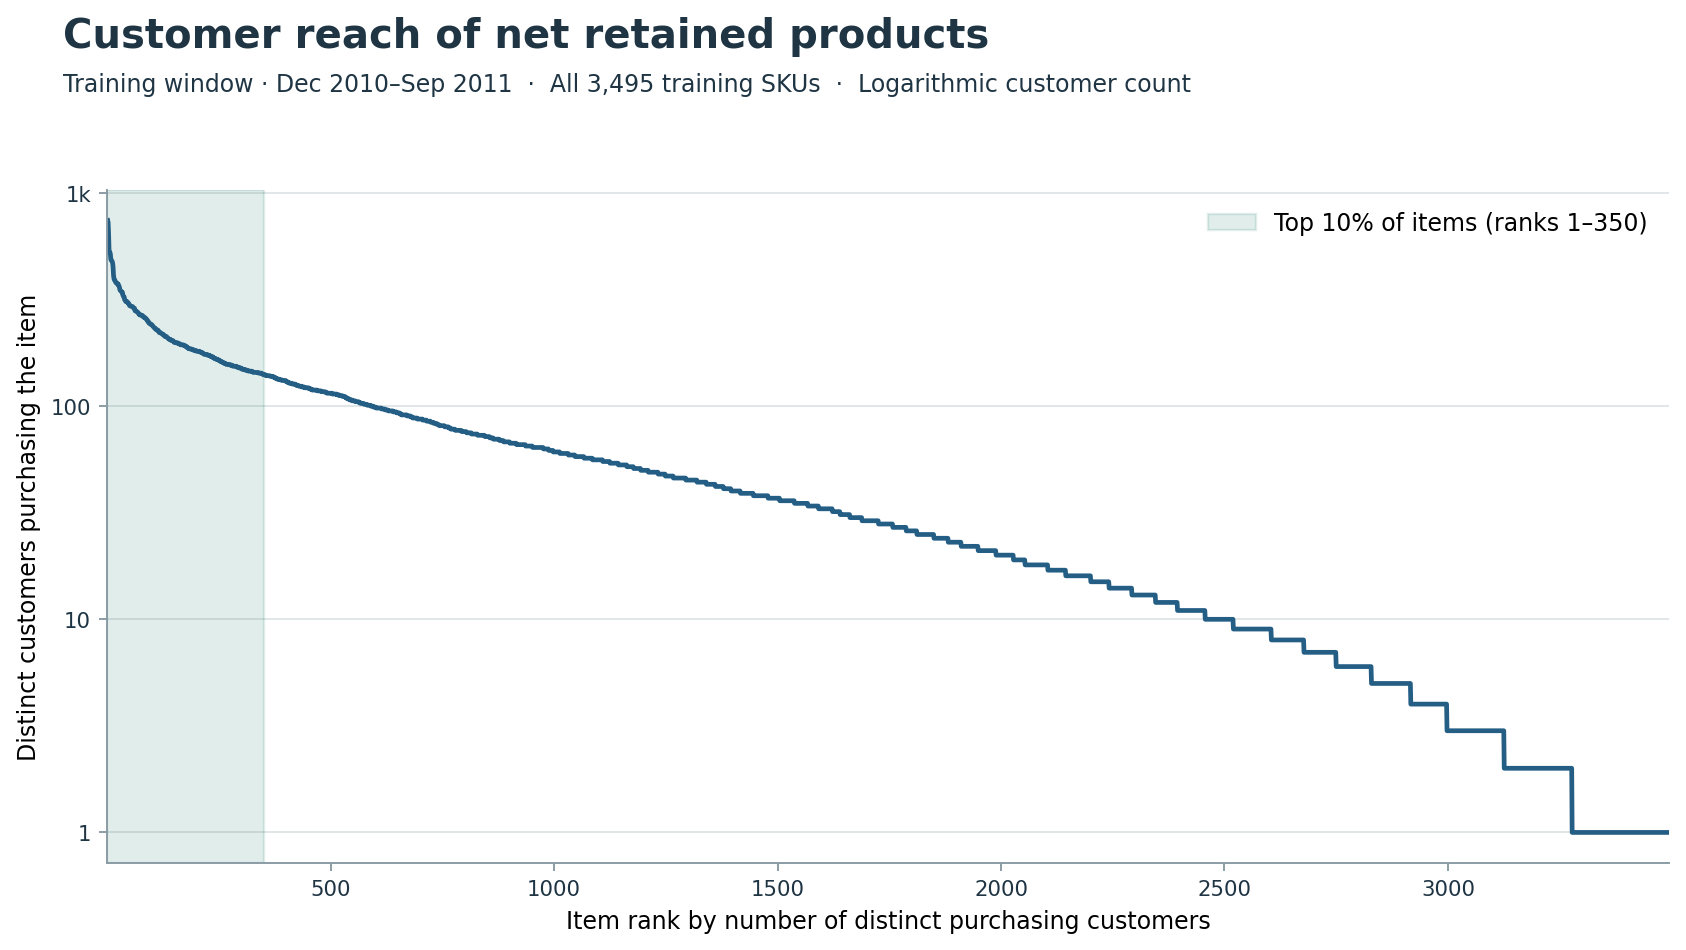

In [14]:
display(Image(filename=str(output_dir / "item_popularity.png"), width=920))